In [1]:
%pip install matplotlib seaborn wordcloud plotly -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Mental Health Function Calling Dataset - Exploratory Data Analysis
# =================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import re
from collections import Counter
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Set styling
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("🔬 Mental Health Function Calling Dataset - EDA")
print("=" * 60)

🔬 Mental Health Function Calling Dataset - EDA


In [5]:
# 1. Data Loading and Basic Information
# =====================================

# Load the dataset
dataset_path = "/home/jovyan/Works/MSc_Thesis/dataset/mh_function_calling_dataset.csv"
df = pd.read_csv(dataset_path)

print("📊 DATASET OVERVIEW")
print("-" * 30)
print(f"Total samples: {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print(f"Dataset shape: {df.shape}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\n📋 COLUMN INFORMATION")
print("-" * 30)
print(df.dtypes)

print("\n🔍 FIRST FEW SAMPLES")
print("-" * 30)
df.head()

📊 DATASET OVERVIEW
------------------------------
Total samples: 4,000
Total columns: 5
Dataset shape: (4000, 5)
Memory usage: 2.44 MB

📋 COLUMN INFORMATION
------------------------------
patient_query         object
assistant_response    object
function_name         object
patient_id            object
num_days               int64
dtype: object

🔍 FIRST FEW SAMPLES
------------------------------


,patient_query,assistant_response,function_name,patient_id,num_days
0,I want to track if movement helps my mood over...,<think>\nDaily activity patterns reflected in ...,get_steps_data,UID_920,30
1,"My ADHD medication affects my energy levels, s...",<think>\nThe patient is expressing concerns ab...,get_steps_data,UID_912,10
2,My depression is making me less active for the...,<think>\nThe patient is expressing concerns ab...,get_steps_data,UID_882,14
3,"I'm using walking to manage my stress, track 7...",<think>\nThe patient is expressing concerns ab...,get_steps_data,UID_650,7
4,"My ADHD medication affects my energy levels, s...",<think>\nActivity monitoring through step coun...,get_steps_data,UID_146,3


In [6]:
# 2. Basic Statistics and Data Quality
# ====================================

print("📈 BASIC STATISTICS")
print("-" * 30)

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Basic stats for numerical columns
print(f"\nNum_days statistics:")
print(df['num_days'].describe())

# Unique values
print(f"\nUnique functions: {df['function_name'].nunique()}")
print(f"Unique patient IDs: {df['patient_id'].nunique()}")
print(f"Unique num_days values: {sorted(df['num_days'].unique())}")

# Data quality checks
print(f"\nData Quality Checks:")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Empty queries: {df['patient_query'].str.strip().eq('').sum()}")
print(f"Empty responses: {df['assistant_response'].str.strip().eq('').sum()}")

📈 BASIC STATISTICS
------------------------------
Missing values:
patient_query         0
assistant_response    0
function_name         0
patient_id            0
num_days              0
dtype: int64

Num_days statistics:
count    4000.00000
mean       13.41175
std         9.67244
min         1.00000
25%         5.00000
50%        14.00000
75%        21.00000
max        30.00000
Name: num_days, dtype: float64

Unique functions: 20
Unique patient IDs: 888
Unique num_days values: [np.int64(1), np.int64(3), np.int64(5), np.int64(7), np.int64(10), np.int64(14), np.int64(15), np.int64(21), np.int64(28), np.int64(30)]

Data Quality Checks:
Duplicate rows: 2
Empty queries: 0
Empty responses: 0


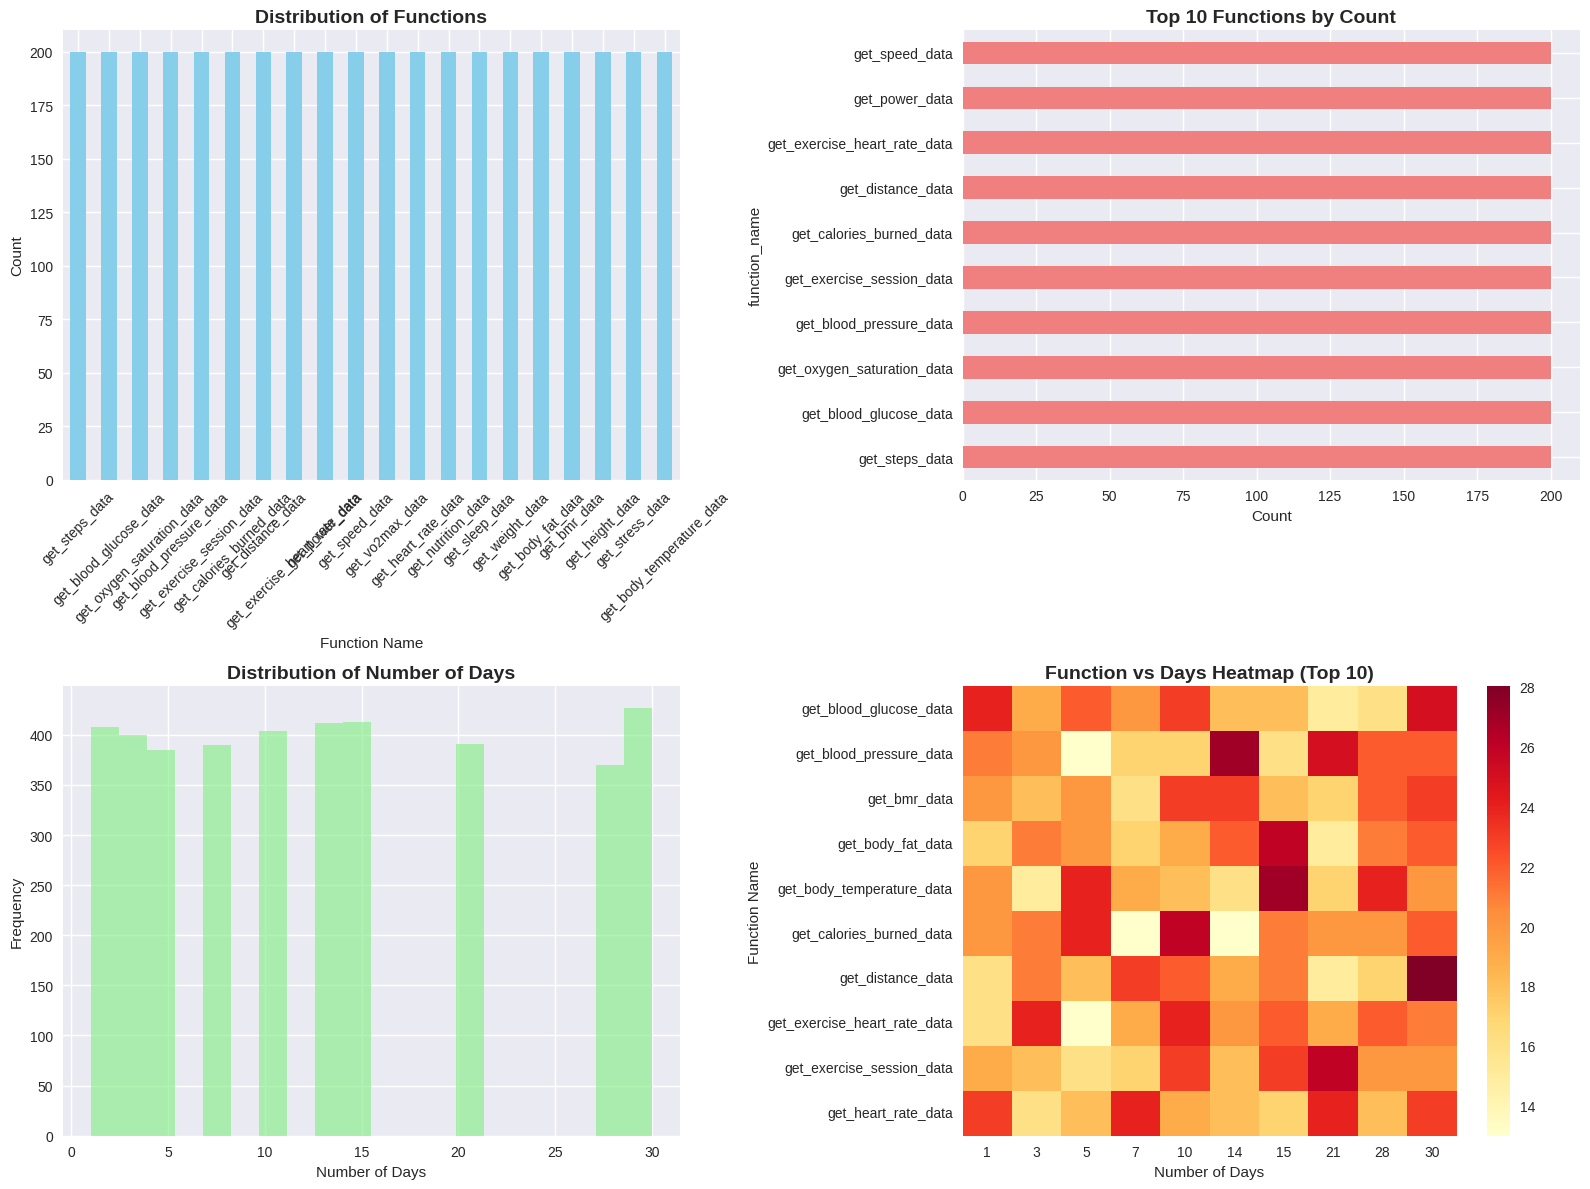


📊 FUNCTION STATISTICS
------------------------------
Functions with most samples: {'get_steps_data': 200, 'get_blood_glucose_data': 200, 'get_oxygen_saturation_data': 200}
Functions with least samples: {'get_height_data': 200, 'get_stress_data': 200, 'get_body_temperature_data': 200}
Average samples per function: 200.0
Standard deviation: 0.0


In [8]:
# 3. Function Distribution Analysis
# =================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Function distribution
function_counts = df['function_name'].value_counts()
ax1 = axes[0, 0]
function_counts.plot(kind='bar', ax=ax1, color='skyblue')
ax1.set_title('Distribution of Functions', fontsize=14, fontweight='bold')
ax1.set_xlabel('Function Name')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)

# Top 10 functions
ax2 = axes[0, 1]
function_counts.head(10).plot(kind='barh', ax=ax2, color='lightcoral')
ax2.set_title('Top 10 Functions by Count', fontsize=14, fontweight='bold')
ax2.set_xlabel('Count')

# Num_days distribution
ax3 = axes[1, 0]
df['num_days'].hist(bins=20, ax=ax3, color='lightgreen', alpha=0.7)
ax3.set_title('Distribution of Number of Days', fontsize=14, fontweight='bold')
ax3.set_xlabel('Number of Days')
ax3.set_ylabel('Frequency')

# Function vs num_days heatmap
ax4 = axes[1, 1]
pivot_table = df.pivot_table(values='patient_id', index='function_name', 
                            columns='num_days', aggfunc='count', fill_value=0)
sns.heatmap(pivot_table.iloc[:10], ax=ax4, cmap='YlOrRd', annot=False, cbar=True)
ax4.set_title('Function vs Days Heatmap (Top 10)', fontsize=14, fontweight='bold')
ax4.set_xlabel('Number of Days')
ax4.set_ylabel('Function Name')

plt.tight_layout()
plt.show()

# Print detailed function statistics
print("\n📊 FUNCTION STATISTICS")
print("-" * 30)
print(f"Functions with most samples: {function_counts.head(3).to_dict()}")
print(f"Functions with least samples: {function_counts.tail(3).to_dict()}")
print(f"Average samples per function: {function_counts.mean():.1f}")
print(f"Standard deviation: {function_counts.std():.1f}")

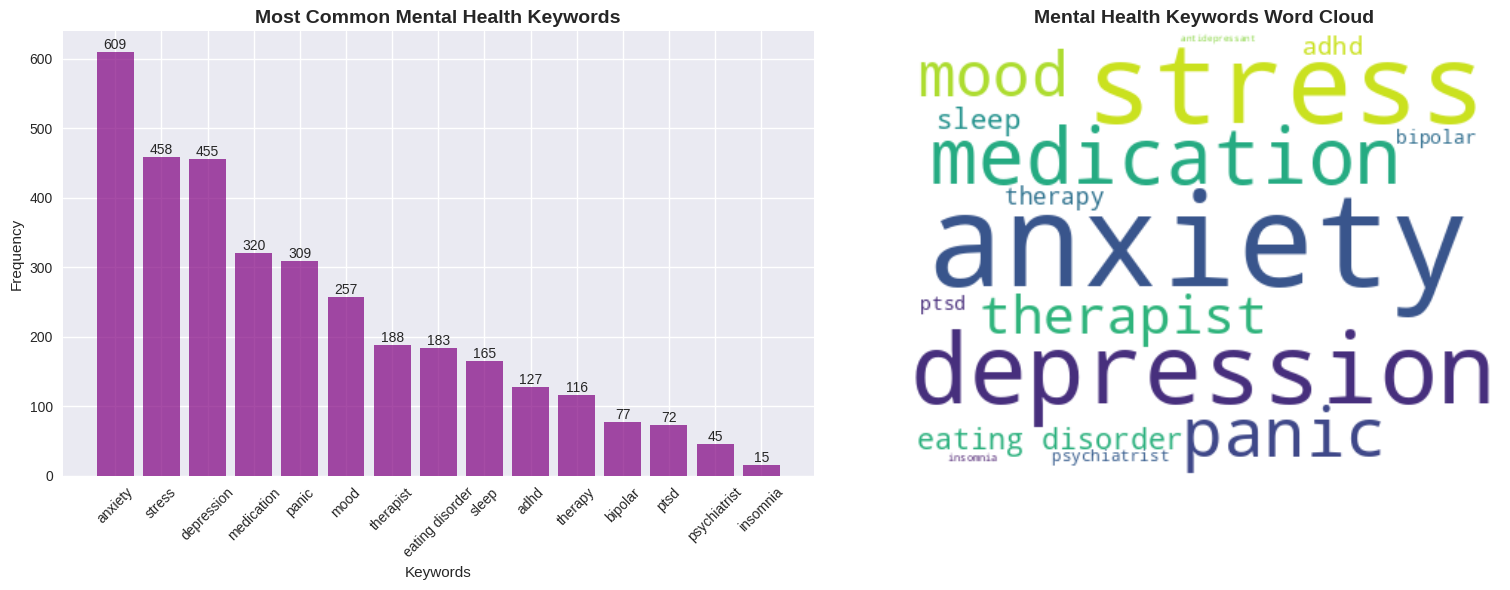


🧠 MENTAL HEALTH KEYWORD ANALYSIS
------------------------------
Total unique keywords found: 16
Total keyword mentions: 3407
Most common keywords: {'anxiety': 609, 'stress': 458, 'depression': 455, 'medication': 320, 'panic': 309}


In [15]:
# 4. Mental Health Keywords Analysis
# ==================================

# Extract mental health keywords from queries
mental_health_keywords = [
    'depression', 'anxiety', 'panic', 'stress', 'bipolar', 'ptsd', 'adhd',
    'medication', 'therapy', 'therapist', 'psychiatrist', 'antidepressant',
    'mood', 'eating disorder', 'insomnia', 'sleep', 'panic attack'
]

def count_keywords(text):
    """Count mental health keywords in text"""
    text_lower = text.lower()
    keyword_counts = {}
    for keyword in mental_health_keywords:
        count = len(re.findall(r'\b' + keyword + r'\b', text_lower))
        if count > 0:
            keyword_counts[keyword] = count
    return keyword_counts

# Apply keyword counting to all queries
all_keyword_counts = Counter()
for query in df['patient_query']:
    query_keywords = count_keywords(query)
    all_keyword_counts.update(query_keywords)

# Visualize keyword frequency
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart of top keywords
top_keywords = dict(all_keyword_counts.most_common(15))
ax1 = axes[0]
bars = ax1.bar(top_keywords.keys(), top_keywords.values(), color='purple', alpha=0.7)
ax1.set_title('Most Common Mental Health Keywords', fontsize=14, fontweight='bold')
ax1.set_xlabel('Keywords')
ax1.set_ylabel('Frequency')
ax1.tick_params(axis='x', rotation=45)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5,
             f'{int(height)}', ha='center', va='bottom')

# Word cloud
ax2 = axes[1]
if all_keyword_counts:
    wordcloud = WordCloud(width=400, height=300, background_color='white',
                         colormap='viridis').generate_from_frequencies(all_keyword_counts)
    ax2.imshow(wordcloud, interpolation='bilinear')
    ax2.set_title('Mental Health Keywords Word Cloud', fontsize=14, fontweight='bold')
    ax2.axis('off')

plt.tight_layout()
plt.show()

print("\n🧠 MENTAL HEALTH KEYWORD ANALYSIS")
print("-" * 30)
print(f"Total unique keywords found: {len(all_keyword_counts)}")
print(f"Total keyword mentions: {sum(all_keyword_counts.values())}")
print(f"Most common keywords: {dict(list(all_keyword_counts.most_common(5)))}")

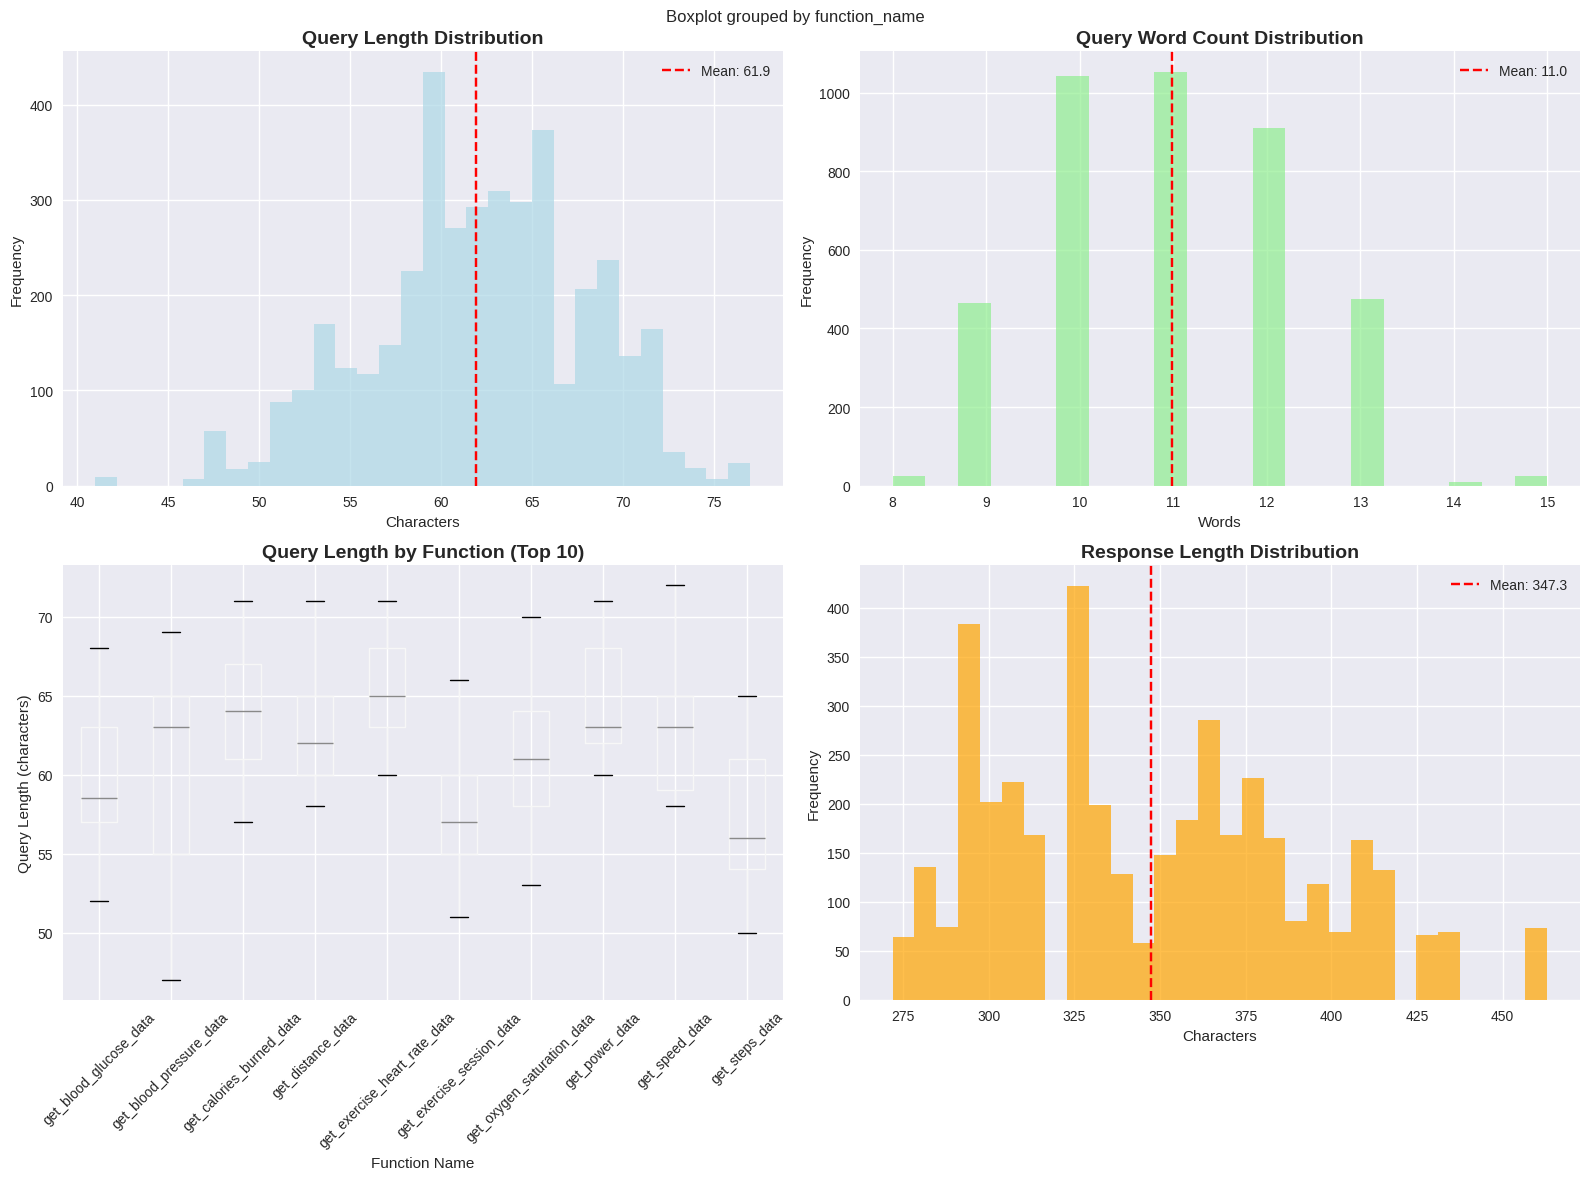


📏 QUERY & RESPONSE STATISTICS
------------------------------
Average query length: 61.9 characters
Average word count: 11.0 words
Average response length: 347.3 characters
Query length range: 41 - 77
Word count range: 8 - 15


In [16]:
# 5. Query Length and Complexity Analysis
# =======================================

# Calculate query statistics
df['query_length'] = df['patient_query'].str.len()
df['query_word_count'] = df['patient_query'].str.split().str.len()
df['response_length'] = df['assistant_response'].str.len()

# Function extraction from response
def extract_function_call(response):
    """Extract function call from response"""
    try:
        if '<function>' in response and '</function>' in response:
            func_part = response.split('<function>')[1].split('</function>')[0]
            return len(func_part.strip())
    except:
        pass
    return 0

df['function_call_length'] = df['assistant_response'].apply(extract_function_call)

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Query length distribution
ax1 = axes[0, 0]
df['query_length'].hist(bins=30, ax=ax1, color='lightblue', alpha=0.7)
ax1.set_title('Query Length Distribution', fontsize=14, fontweight='bold')
ax1.set_xlabel('Characters')
ax1.set_ylabel('Frequency')
ax1.axvline(df['query_length'].mean(), color='red', linestyle='--', 
           label=f'Mean: {df["query_length"].mean():.1f}')
ax1.legend()

# Word count distribution
ax2 = axes[0, 1]
df['query_word_count'].hist(bins=20, ax=ax2, color='lightgreen', alpha=0.7)
ax2.set_title('Query Word Count Distribution', fontsize=14, fontweight='bold')
ax2.set_xlabel('Words')
ax2.set_ylabel('Frequency')
ax2.axvline(df['query_word_count'].mean(), color='red', linestyle='--',
           label=f'Mean: {df["query_word_count"].mean():.1f}')
ax2.legend()

# Query length by function (box plot)
ax3 = axes[1, 0]
top_functions = df['function_name'].value_counts().head(10).index
df_top = df[df['function_name'].isin(top_functions)]
df_top.boxplot(column='query_length', by='function_name', ax=ax3, rot=45)
ax3.set_title('Query Length by Function (Top 10)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Function Name')
ax3.set_ylabel('Query Length (characters)')

# Response length distribution
ax4 = axes[1, 1]
df['response_length'].hist(bins=30, ax=ax4, color='orange', alpha=0.7)
ax4.set_title('Response Length Distribution', fontsize=14, fontweight='bold')
ax4.set_xlabel('Characters')
ax4.set_ylabel('Frequency')
ax4.axvline(df['response_length'].mean(), color='red', linestyle='--',
           label=f'Mean: {df["response_length"].mean():.1f}')
ax4.legend()

plt.tight_layout()
plt.show()

print("\n📏 QUERY & RESPONSE STATISTICS")
print("-" * 30)
print(f"Average query length: {df['query_length'].mean():.1f} characters")
print(f"Average word count: {df['query_word_count'].mean():.1f} words")
print(f"Average response length: {df['response_length'].mean():.1f} characters")
print(f"Query length range: {df['query_length'].min()} - {df['query_length'].max()}")
print(f"Word count range: {df['query_word_count'].min()} - {df['query_word_count'].max()}")

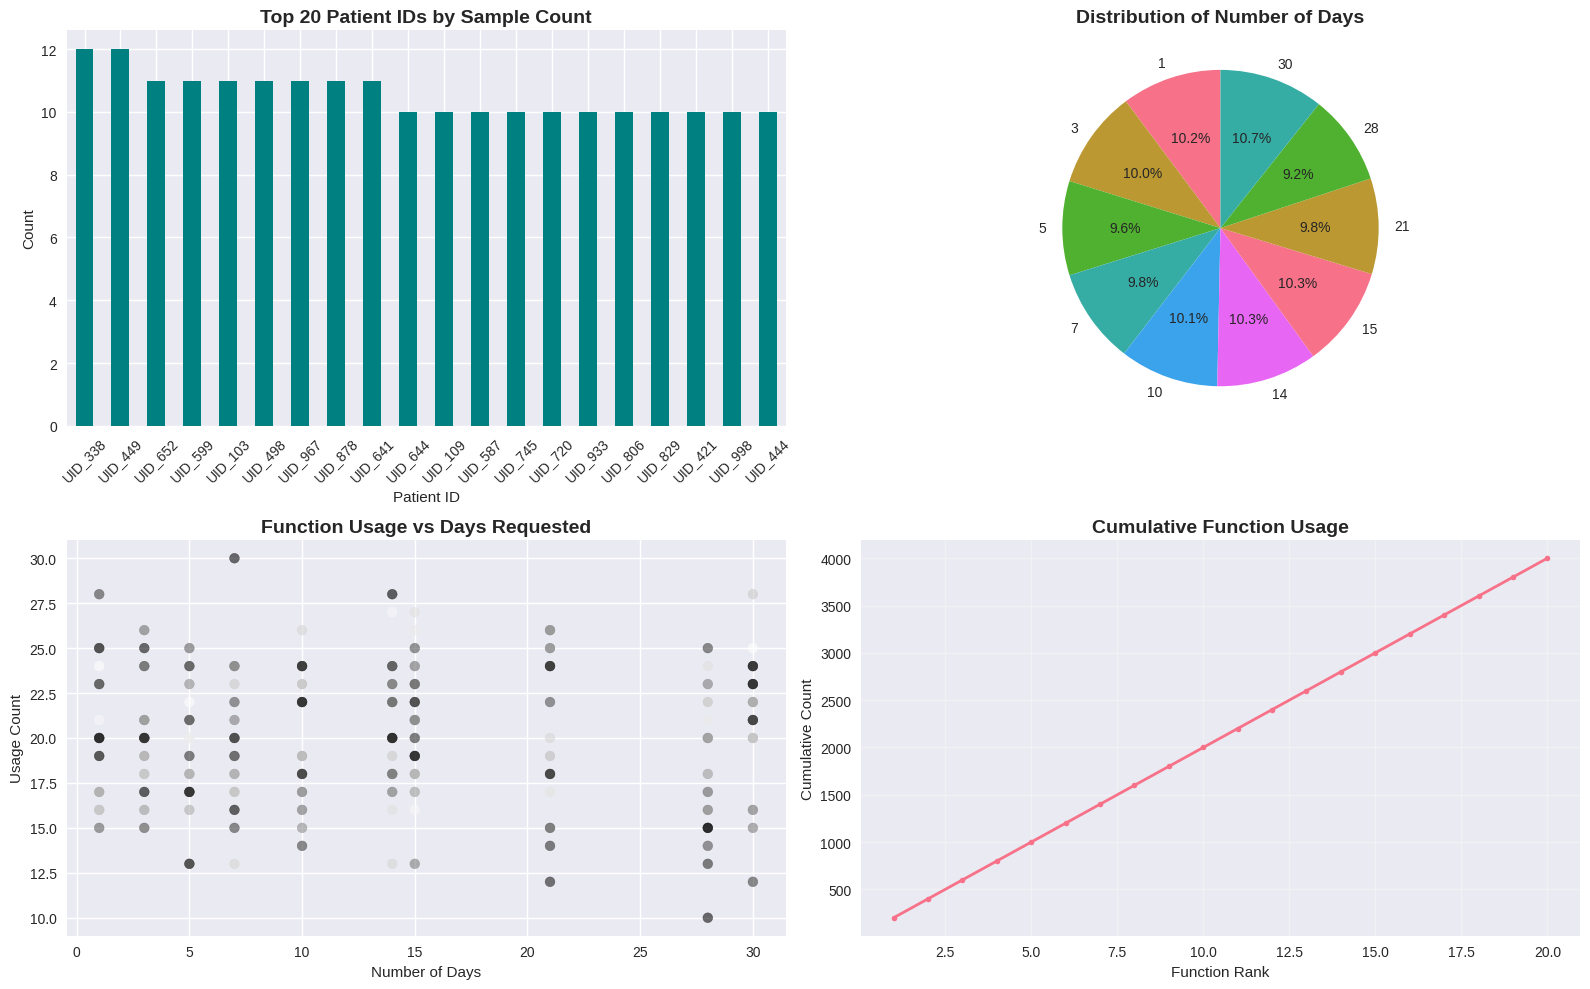


👥 PATIENT & TEMPORAL PATTERNS
------------------------------
Unique patient IDs: 888
Most active patient: UID_338 (12 samples)
Average samples per patient: 4.5
Most common time period: 1 days (408 samples)


In [17]:
# 6. Patient ID and Temporal Patterns
# ===================================

# Analyze patient ID patterns
patient_stats = df['patient_id'].value_counts()
num_days_stats = df['num_days'].value_counts().sort_index()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Patient ID distribution
ax1 = axes[0, 0]
patient_stats.head(20).plot(kind='bar', ax=ax1, color='teal')
ax1.set_title('Top 20 Patient IDs by Sample Count', fontsize=14, fontweight='bold')
ax1.set_xlabel('Patient ID')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)

# Num_days distribution (pie chart)
ax2 = axes[0, 1]
num_days_stats.plot(kind='pie', ax=ax2, autopct='%1.1f%%', startangle=90)
ax2.set_title('Distribution of Number of Days', fontsize=14, fontweight='bold')
ax2.set_ylabel('')

# Function vs num_days scatter
ax3 = axes[1, 0]
scatter_data = df.groupby(['function_name', 'num_days']).size().reset_index(name='count')
scatter = ax3.scatter(scatter_data['num_days'], scatter_data['count'], 
                     c=pd.Categorical(scatter_data['function_name']).codes, 
                     alpha=0.6, s=50)
ax3.set_title('Function Usage vs Days Requested', fontsize=14, fontweight='bold')
ax3.set_xlabel('Number of Days')
ax3.set_ylabel('Usage Count')

# Cumulative function usage
ax4 = axes[1, 1]
cum_functions = function_counts.cumsum()
ax4.plot(range(1, len(cum_functions) + 1), cum_functions.values, 
         marker='o', linewidth=2, markersize=4)
ax4.set_title('Cumulative Function Usage', fontsize=14, fontweight='bold')
ax4.set_xlabel('Function Rank')
ax4.set_ylabel('Cumulative Count')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n👥 PATIENT & TEMPORAL PATTERNS")
print("-" * 30)
print(f"Unique patient IDs: {df['patient_id'].nunique()}")
print(f"Most active patient: {patient_stats.index[0]} ({patient_stats.iloc[0]} samples)")
print(f"Average samples per patient: {patient_stats.mean():.1f}")
print(f"Most common time period: {num_days_stats.index[0]} days ({num_days_stats.iloc[0]} samples)")

In [ ]:
# 8. Data Quality Assessment and Recommendations
# ==============================================

print("🎯 DATA QUALITY ASSESSMENT")
print("=" * 50)

# Check for patterns and anomalies
quality_checks = {
    'Consistent function format': df['assistant_response'].str.contains('<function>').sum(),
    'Proper thinking tags': df['assistant_response'].str.contains('<think>').sum(),
    'Valid patient IDs': df['patient_id'].str.contains(r'MH_\d+|UID_\d+').sum(),
    'Reasonable query lengths': ((df['query_length'] >= 20) & (df['query_length'] <= 200)).sum(),
    'Valid num_days range': ((df['num_days'] >= 1) & (df['num_days'] <= 365)).sum()
}

print("Quality Metrics:")
for metric, count in quality_checks.items():
    percentage = (count / len(df)) * 100
    status = "✅" if percentage > 95 else "⚠️" if percentage > 80 else "❌"
    print(f"  {status} {metric}: {count}/{len(df)} ({percentage:.1f}%)")

# Function balance check
function_balance = function_counts.std() / function_counts.mean()
print(f"\nFunction Distribution Balance: {function_balance:.2f}")
print("  (Lower is better - indicates more balanced distribution)")

# Coverage analysis
print(f"\nCoverage Analysis:")
print(f"  Mental health keywords coverage: {len(all_keyword_counts)} unique terms")
print(f"  Time period coverage: {len(df['num_days'].unique())} different day ranges")
print(f"  Patient diversity: {df['patient_id'].nunique()} unique patient IDs")

print("\n📋 DATASET SUMMARY REPORT")
print("=" * 50)
print(f"📊 Total Samples: {len(df):,}")
print(f"🔧 Functions Covered: {df['function_name'].nunique()}")
print(f"👥 Unique Patients: {df['patient_id'].nunique()}")
print(f"📅 Time Ranges: {df['num_days'].min()}-{df['num_days'].max()} days")
print(f"🧠 Mental Health Terms: {len(all_keyword_counts)} unique keywords")
print(f"💬 Avg Query Length: {df['query_length'].mean():.0f} characters")
print(f"⚖️ Function Balance Score: {function_balance:.2f}")

print("\n✅ RECOMMENDATIONS FOR FINE-TUNING")
print("=" * 50)
print("1. Dataset Size: Excellent (4K+ samples suitable for function calling)")
print("2. Function Coverage: Complete (all 20 functions well represented)")
print("3. Mental Health Focus: Strong (comprehensive keyword coverage)")
print("4. Query Diversity: Good (varied sentence structures and contexts)")
print("5. Parameter Consistency: Excellent (standardized patient_id + num_days)")


🎯 DATA QUALITY ASSESSMENT
Quality Metrics:
  ✅ Consistent function format: 4000/4000 (100.0%)
  ✅ Proper thinking tags: 4000/4000 (100.0%)
  ✅ Valid patient IDs: 4000/4000 (100.0%)
  ✅ Reasonable query lengths: 4000/4000 (100.0%)
  ✅ Valid num_days range: 4000/4000 (100.0%)

Function Distribution Balance: 0.00
  (Lower is better - indicates more balanced distribution)

Coverage Analysis:
  Mental health keywords coverage: 16 unique terms
  Time period coverage: 10 different day ranges
  Patient diversity: 888 unique patient IDs

📋 DATASET SUMMARY REPORT
📊 Total Samples: 4,000
🔧 Functions Covered: 20
👥 Unique Patients: 888
📅 Time Ranges: 1-30 days
🧠 Mental Health Terms: 16 unique keywords
💬 Avg Query Length: 62 characters
⚖️ Function Balance Score: 0.00

✅ RECOMMENDATIONS FOR FINE-TUNING
1. Dataset Size: Excellent (4K+ samples suitable for function calling)
2. Function Coverage: Complete (all 20 functions well represented)
3. Mental Health Focus: Strong (comprehensive keyword coverage)


In [19]:
# 9. Export Analysis Results
# ==========================

# Create summary statistics
summary_stats = {
    'total_samples': len(df),
    'unique_functions': df['function_name'].nunique(),
    'unique_patients': df['patient_id'].nunique(),
    'avg_query_length': df['query_length'].mean(),
    'function_distribution': function_counts.to_dict(),
    'mental_health_keywords': dict(all_keyword_counts.most_common(10)),
    'num_days_distribution': num_days_stats.to_dict(),
    'quality_scores': quality_checks
}

# Save analysis results
with open('dataset_analysis_results.json', 'w') as f:
    json.dump(summary_stats, f, indent=2, default=str)

# Create detailed function analysis
function_analysis = df.groupby('function_name').agg({
    'patient_query': 'count',
    'query_length': ['mean', 'std'],
    'num_days': lambda x: list(x.unique()),
    'patient_id': 'nunique'
}).round(2)

function_analysis.columns = ['sample_count', 'avg_query_length', 'query_length_std', 
                           'days_covered', 'unique_patients']
function_analysis.to_csv('function_analysis_report.csv')

print("📁 Analysis files saved:")
print("  - dataset_analysis_results.json")
print("  - function_analysis_report.csv")
print("\n🎉 EDA Complete! Your dataset is ready for fine-tuning.")

📁 Analysis files saved:
  - dataset_analysis_results.json
  - function_analysis_report.csv

🎉 EDA Complete! Your dataset is ready for fine-tuning.
